# CellSegNet — nnUNet-style 3D Cell Segmentation

This notebook covers:
1. **Data exploration** — inspect the training NPZ files and visualise the targets
2. **Launch training** — run the training loop from here
3. **Inference & visualisation** — load a checkpoint and segment a new volume

In [72]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import sys
sys.path.insert(0, "../src")

import torch
import argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pathlib import Path

In [ ]:
from segmentation.train import train
from segmentation.targets import compute_all_targets

from segmentation.model import CellSegNet
from segmentation.dataset import CellSegDataset
from segmentation.losses import CellSegLoss

from segmentation.plot import plot_sample, plot_offsets, plot_preds
from segmentation.predict import load_model, predict_volume, postprocess, sigmoid
from segmentation.post_process import postprocess

In [ ]:
from params import *
from utils.metrics import *
from utils.plot import *

### Data

In [73]:
DATA_DIR = Path("../output/segs_3/")

npz_files = sorted(DATA_DIR.glob("*.npz"))
print(f"Found {len(npz_files)} training file(s)")

Found 10000 training file(s)


In [89]:
data = np.load(npz_files[0], allow_pickle=False)

print("Keys and shapes:")
for k in data.files:
    try:
        v = data[k]
        print(f"  {k:12s}  shape={v.shape}  dtype={v.dtype}")
    except Exception as e:
        print(f"  {k:12s}  *** corrupt: {e} ***")

img = data['img'] # (D, H, W) uint16
masks = data['masks']  # (D, H, W) uint16 instance labels
centroids = data['centroids']  # (N, 3) int32

fg_soft = (masks > 0).astype(np.float32)

D, H, W = img.shape
print(f"\nVolume    : {D} × {H} × {W}")
print(
    f"Cells     : {len(np.unique(masks)) - 1} in masks | {len(centroids)} centroids (may span multiple frames)"
)

Keys and shapes:
  img           shape=(64, 256, 256)  dtype=uint16
  masks         shape=(64, 256, 256)  dtype=uint16
  cellpose_masks  shape=(64, 256, 256)  dtype=uint16
  flows         shape=(64, 256, 256, 3)  dtype=uint8
  probas        shape=(64, 256, 256)  dtype=float32
  centroids     shape=(201, 3)  dtype=int32

Volume    : 64 × 256 × 256
Cells     : 201 in masks | 201 centroids (may span multiple frames)


In [90]:
heatmap, offsets, centroid_map = compute_all_targets(masks, sigma=3.0)

print(f"heatmap : {heatmap.shape}  range [{heatmap.min():.3f}, {heatmap.max():.3f}]")
print(
    f"offsets : {offsets.shape}  range [{offsets.min():.3f}, {offsets.max():.3f}]  (normalised to ~[-1,1])"
)
print(f"Cells derived from masks: {len(centroid_map)}")

heatmap : (64, 256, 256)  range [0.000, 0.999]
offsets : (3, 64, 256, 256)  range [-25.556, 25.444]  (normalised to ~[-1,1])
Cells derived from masks: 201


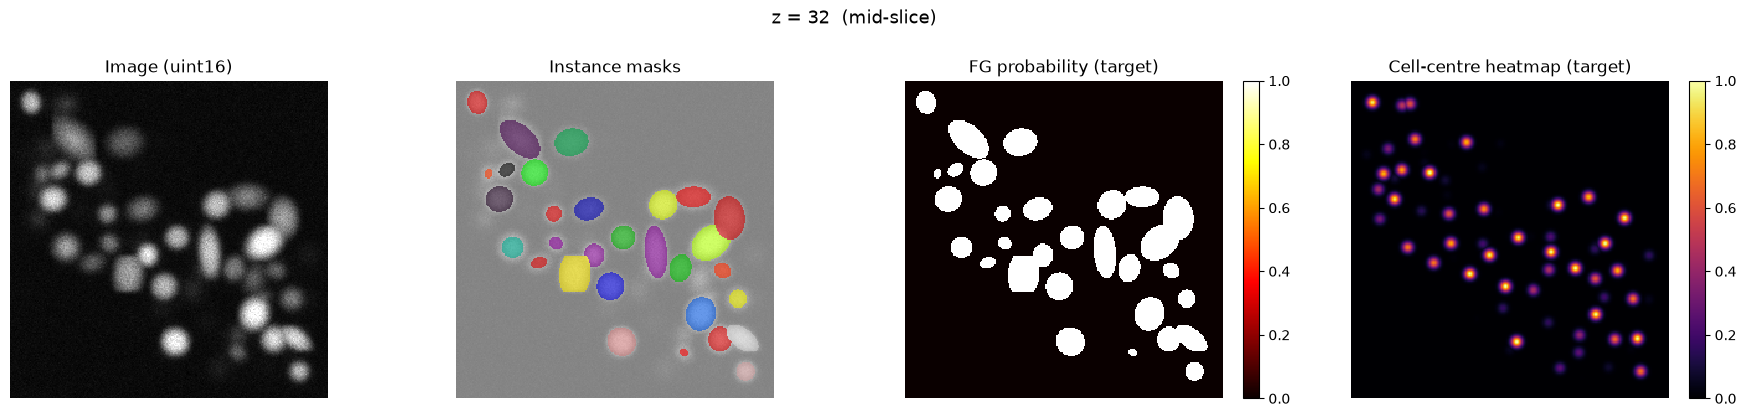

In [91]:
plot_sample(img, masks, fg_soft, heatmap, z=32)

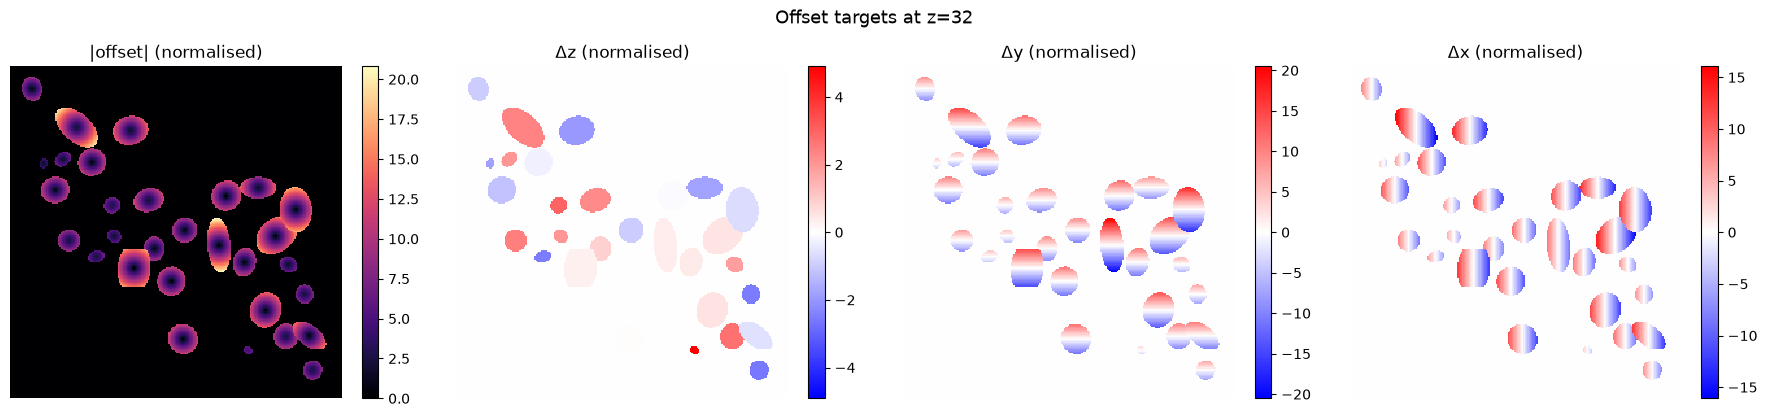

In [99]:
plot_offsets(offsets)

### Dataset

In [87]:
ds = CellSegDataset(
    str(DATA_DIR), sigma=3.0, augment=False, use_cellpose=True
)

print(f"Dataset: {len(ds)} sample(s)")

Dataset: 10000 sample(s)


In [88]:
sample = ds[0]
print("Sample keys/shapes:")
for k, v in sample.items():
    print(f"  {k:10s}  {tuple(v.shape)}  {v.dtype}")

Sample keys/shapes:
  image       (2, 64, 256, 256)  torch.float32
  fg          (64, 256, 256)  torch.float32
  heatmap     (64, 256, 256)  torch.float32
  offsets     (3, 64, 256, 256)  torch.float32
  fg_mask     (64, 256, 256)  torch.bool
  flows       (64, 256, 256, 3)  torch.uint8
  probas      (64, 256, 256)  torch.float32


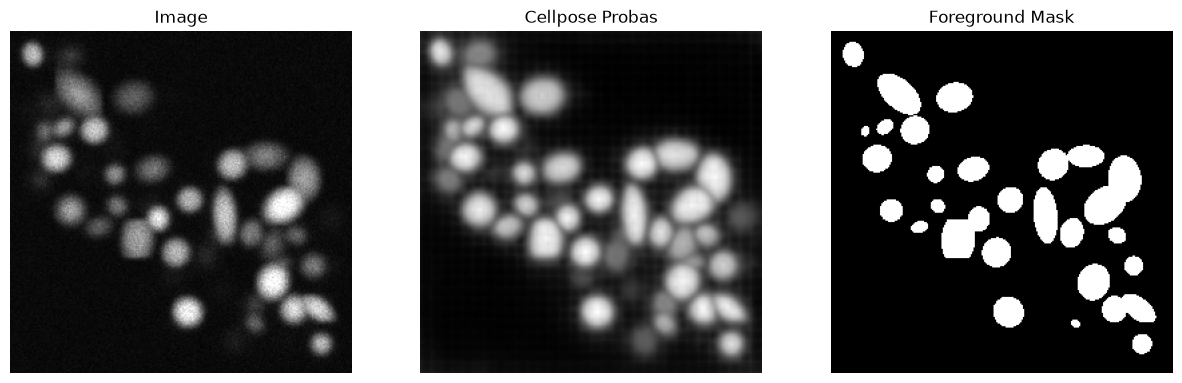

In [112]:
z = 32
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(sample["image"][0][z], cmap="gray")
plt.axis(False)
plt.title("Image")
plt.subplot(1, 3, 2)
plt.imshow(sample["image"][1][z], cmap="gray")
plt.axis(False)
plt.title("Cellpose Probas")
plt.subplot(1, 3, 3)
plt.imshow(sample["fg_mask"][z], cmap="gray")
plt.axis(False)
plt.title("Foreground Mask")
plt.show()

### Model

In [113]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

model = CellSegNet(features=(32, 64, 128, 256, 256), in_channels=2)
model.to(device)
print(f"Parameters: {model.count_parameters() / 1e6:.1f}M")

Device: cuda
Parameters: 20.0M


In [114]:
y = model(sample["image"].unsqueeze(0).to(device))

for k in y:
    print(k, y[k].shape)

fg_logits torch.Size([1, 1, 64, 256, 256])
heatmap_logits torch.Size([1, 1, 64, 256, 256])
offsets torch.Size([1, 3, 64, 256, 256])


### Training

In [116]:
MODEL_DIR = Path("../output/nnunet_v5/")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [117]:
args = argparse.Namespace(
    data_dir=str(DATA_DIR),
    output_dir=str(MODEL_DIR),
    use_cellpose=True,
    epochs=1,
    lr=3e-4,
    batch_size=8,
    sigma=3.0,
    features="32,64,128,256,256",
    # patch_size=None,  # None = full 64×256×256 volume
    patch_size='64,64,64', # use this when memory is tight
    num_workers=8,  # 0 = load in main process (safe in notebooks)
    w_fg=1.0,
    w_center=1.0,
    w_heatmap=1.0,
    w_offset=1.0,
    log_every=50,
    save_every=200,
    warmup_ratio=0,
    fp16=True,
)

In [ ]:
train(args)

Using device: cuda
Precision: FP16 mixed precision
Dataset: 10000 volumes, patch_size=(64, 64, 64)
Model parameters: 20.0M


/data/kaggle-cell-tracking/notebooks/../src/segmentation/train.py:70: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  ).to(device)


epoch    1/1 - step     50/1250 | lr=2.88e-04 | loss=3.418 | fg=0.913 - center=0.315 - offset=2.190
epoch    1/1 - step    100/1250 | lr=2.76e-04 | loss=1.653 | fg=0.413 - center=0.138 - offset=1.101
epoch    1/1 - step    150/1250 | lr=2.64e-04 | loss=1.205 | fg=0.297 - center=0.118 - offset=0.790
epoch    1/1 - step    200/1250 | lr=2.52e-04 | loss=1.015 | fg=0.262 - center=0.107 - offset=0.646
epoch    1/1 - step    250/1250 | lr=2.40e-04 | loss=0.899 | fg=0.241 - center=0.107 - offset=0.550
epoch    1/1 - step    300/1250 | lr=2.28e-04 | loss=0.819 | fg=0.207 - center=0.103 - offset=0.509
epoch    1/1 - step    350/1250 | lr=2.16e-04 | loss=0.772 | fg=0.199 - center=0.097 - offset=0.476


### Inference

In [ ]:
checkpoints = sorted(MODEL_DIR.glob("*.pt"))
if not checkpoints:
    print("No checkpoint found — run training first.")
else:
    ckpt_path = checkpoints[-1]  # latest checkpoint
    print(f"Loading: {ckpt_path.name}")

    infer_model = load_model(str(ckpt_path), device=device)
    print("Model loaded.")

In [ ]:
target_npz = npz_files[0]  # change index to run on a different file
vol_data = np.load(target_npz, allow_pickle=False)

try:
    vol_img = vol_data["img"]
except Exception as e:
    raise RuntimeError(f"Could not load 'img' from {target_npz}: {e}")

preds = predict_volume(infer_model, vol_img, device=device)
print("Raw predictions:")
for k, v in preds.items():
    print(f"  {k:20s}  {v.shape}  [{v.min():.3f}, {v.max():.3f}]")

In [ ]:
pred_fg = sigmoid(preds["fg_logits"])  # (D, H, W)  in [0,1]
pred_heatmap = sigmoid(preds["heatmap_logits"])  # (D, H, W)  in [0,1]
pred_offsets = preds["offsets"]  # (3, D, H, W) normalised

In [ ]:
pred_masks, pred_centroids = postprocess(
    preds,
    # fg_thresh=0.5,
    # vote_sigma=2.0,
    # nms_size=7,
    # vote_thresh_rel=0.1,
    # min_vote_voxels=10,
)

n_pred = len(pred_centroids)
n_gt = len(centroid_map)
print(f"Predicted cells : {n_pred}")
print(f"GT cells (masks): {n_gt}")

In [ ]:
plot_preds(vol_img, masks, fg_soft, heatmap, pred_masks, pred_centroids, pred_fg, pred_heatmap, z=32)

In [ ]:
plot_offsets(pred_offsets * pred_fg[None])

### Real Data

In [ ]:
sample_name = "6bba_09961292"

frame = 56

img = np.load(IMG_FOLDER + f"{sample_name}_{frame}.npy")

nodes = pd.read_csv(NODES_FOLDER + f"{sample_name}.csv")
gt = nodes[nodes["t"] == frame][["z", "y", "x"]].values

In [ ]:
preds = predict_volume(infer_model, img, device=device)
print("Raw predictions:")
for k, v in preds.items():
    print(f"  {k:20s}  {v.shape}  [{v.min():.3f}, {v.max():.3f}]")

In [ ]:
pred_masks, pred_centroids = postprocess(
    preds,
    # fg_thresh=0.5,
    # vote_sigma=2.0,
    # nms_size=7,
    # vote_thresh_rel=0.1,
    # min_vote_voxels=10,
)

n_pred = len(pred_centroids)
print(f"Predicted cells : {n_pred}")

In [69]:
z = 1

pred_fg = sigmoid(preds["fg_logits"])  # (D, H, W)  in [0,1]
pred_heatmap = sigmoid(preds["heatmap_logits"])  # (D, H, W)  in [0,1]
pred_offsets = preds["offsets"]  # (3, D, H, W) normalised

plot_preds(
    img,
    pred_masks=pred_masks,
    pred_centroids=pred_centroids,
    pred_fg=pred_fg,
    pred_heatmap=pred_heatmap,
    z=z
)

In [70]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    pred_centroids,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

In [ ]:
mask = np.where(pred_masks > 0, pred_masks, np.nan)
tol = 3

# ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else [7]
ids = np.unique(gt[:, 0])

for i in ids:    
    plt.figure(figsize=(7, 7))
    plt.title(f"Z = {i}")
    plot_contours(img[i], mask[i])
    # break
    scatter_plot_center_preds(
        pred_centroids, matched_gt, unmatched_gt, frame=i, tol=tol
    )
    plt.show()

    break

#### Save predictions

In [ ]:
SAVE_DIR = MODEL_DIR / "preds"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
out_path = SAVE_DIR / "pred_vol_00000.npz"

np.savez_compressed(
    out_path,
    masks=pred_masks,
    centroids=pred_centroids,
    fg_prob=pred_fg,
    heatmap=pred_heatmap,
)
print(f"Saved to {out_path}")

Done 